In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: []


In [4]:
from tensorflow.keras.datasets import imdb

# Load the IMDb dataset
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=10000)

print("Training reviews:", len(x_train))
print("Testing reviews:", len(x_test))

print("\nFirst review (encoded):")
print(x_train[0])

print("\nSentiment label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000

First review (encoded):
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 

In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Set the maximum review length
max_length = 200

# Make all reviews the same length
x_train_padded = pad_sequences(
    x_train, maxlen=max_length, padding='post', truncating='post'
)

x_test_padded = pad_sequences(
    x_test, maxlen=max_length, padding='post', truncating='post'
)

print("Training data shape:", x_train_padded.shape)
print("Testing data shape:", x_test_padded.shape)
print("Length of first review:", len(x_train_padded[0]))

Training data shape: (25000, 200)
Testing data shape: (25000, 200)
Length of first review: 200


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Build the LSTM model
model = Sequential([
    Embedding(input_dim=10000, output_dim=64, mask_zero=True),
    LSTM(64),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

# Configure the model for training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Train the LSTM model
history = model.fit(
    x_train_padded,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 65s 200ms/step - accuracy: 0.7777 - loss: 0.4512 - val_accuracy: 0.8614 - val_loss: 0.3386
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 57s 181ms/step - accuracy: 0.8964 - loss: 0.2699 - val_accuracy: 0.8636 - val_loss: 0.3244
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 88s 200ms/step - accuracy: 0.9224 - loss: 0.2084 - val_accuracy: 0.8596 - val_loss: 0.4206
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 62s 198ms/step - accuracy: 0.9330 - loss: 0.1751 - val_accuracy: 0.8560 - val_loss: 0.4080
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 62s 198ms/step - accuracy: 0.9567 - loss: 0.1196 - val_accuracy: 0.8568 - val_loss: 0.4452


In [8]:
# Evaluate the model using the test dataset
test_loss, test_accuracy = model.evaluate(
    x_test_padded,
    y_test,
    verbose=1
)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 27s 35ms/step - accuracy: 0.8391 - loss: 0.4963

Test Loss: 0.4963
Test Accuracy: 83.91 %


In [9]:

import re
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load the IMDb word index
word_index = imdb.get_word_index()

def predict_sentiment(review):

    # Clean the review and extract words
    words = re.findall(r"[a-z]+", review.lower())

    # Convert words into numerical IDs
    encoded_review = [1]

    for word in words:
        index = word_index.get(word)

        if index is None or index + 3 >= 10000:
            encoded_review.append(2)
        else:
            encoded_review.append(index + 3)

    # Pad the review to 200 tokens
    padded_review = pad_sequences(
        [encoded_review],
        maxlen=200,
        padding="post",
        truncating="post"
    )

    # Predict sentiment using the trained model
    score = float(model.predict(padded_review, verbose=0)[0][0])

    # Display the result
    if score >= 0.5:
        print("Sentiment: Positive 😊")
    else:
        print("Sentiment: Negative 😞")

    print(f"Positive sentiment score: {score:.2%}")


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step


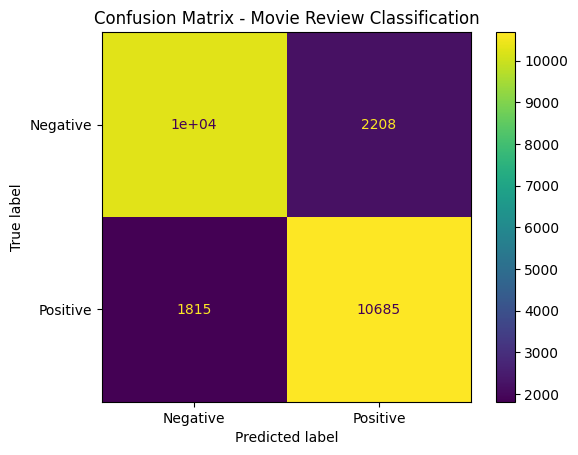

Classification Report:

              precision    recall  f1-score   support

    Negative     0.8501    0.8234    0.8365     12500
    Positive     0.8287    0.8548    0.8416     12500

    accuracy                         0.8391     25000
   macro avg     0.8394    0.8391    0.8390     25000
weighted avg     0.8394    0.8391    0.8390     25000



In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Predict sentiment for all test reviews
y_prob = model.predict(x_test_padded, verbose=1)

# Convert probabilities into binary labels
y_pred = (y_prob.ravel() >= 0.5).astype(int)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot()
plt.title("Confusion Matrix - Movie Review Classification")
plt.show()

# Print classification report
print("Classification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"],
        digits=4
    )
)

**Enter Movie Review here**

In [11]:
# Enter your movie review
review = input("Enter your movie review: ")

# Predict the sentiment
predict_sentiment(review)

Enter your movie review: predict_sentiment("Despite the excellent actors and beautiful visuals, the movie was boring and disappointing.")
Sentiment: Negative 😞
Positive sentiment score: 33.92%


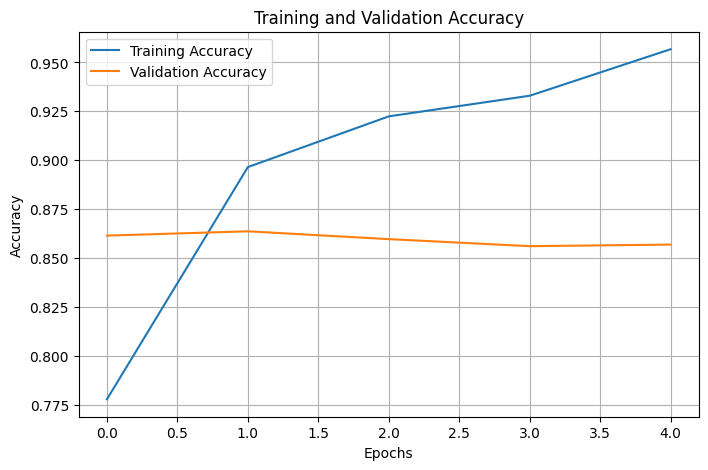

In [12]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()